# Reordering headroom — is there anything to reorder?

`WindowInsertionPolicy` never reorders. Once a request's pickup and dropoff are
spliced in at positions *(i, j)*, their position relative to every other event
is frozen for the lifetime of that schedule: `Schedule` offers `insert`,
`without_owner` and `without_pickup`, and nothing that **moves** an event.

Dynamic route reordering — re-optimising the visit order while holding the
request set fixed — is the standard companion to insertion construction in the
dial-a-ride literature, and it is the obvious next direction to explore. Before
building any of it, this notebook answers a much cheaper question: **is there a
search space at all?**

A reorder step handed a schedule that typically holds two requests has nothing
to do. One handed a schedule holding eight has real room to work. We have never
measured which of those we have.

## What is instrumented

`InstrumentedPolicy` subclasses `WindowInsertionPolicy` with counting overrides
that delegate straight up, so behaviour is unchanged — the same pattern as
`CountingWindowInsertionPolicy` in `window-width-sweep-2.ipynb`. Nothing under
`src/` is touched.

| Quantity | Where it comes from |
| --- | --- |
| Requests in the schedule | `len(schedule.owners())`, sampled after each `plan` |
| Events in the schedule | `len(schedule)`, sampled after each `plan` |
| Adoption rate | `_adopt_dropoff` calls per `plan` call |
| Rejection-trigger rate | `plan` calls where `_best_insertion` returned `None` at least once |

The first two size the search space. The last two test two specific claims made
when this direction was proposed.

## The questions, and what would settle them

Written down before the run, so that a null result is as informative as a
positive one.

### Q1 — is there a search space?

The decisive number is the **median count of distinct requests in the
schedule**, because pair-relocate — the operator that would do the actual work
— ejects and reinserts *requests*, not individual events.

- **Median >= 5** → real headroom. Local search has somewhere to go and
  building it is justified.
- **Median <= 2 and P90 <= 3** → there is essentially nothing to reorder. The
  direction should be dropped, or pursued only under load (see Q4).
- **Anything between** → marginal. Read the P90 and the ">= 4 requests" row
  instead: if the tail is fat, a reorder step still earns its keep on the
  minority of calls where it matters.

### Q2 — does opportunistic boarding actually perturb the order?

The proposal argued that `_adopt_dropoff` is a live degradation source. When
`BusAgent._board` boards a rider this policy deliberately rejected, the policy
is *forced* to splice in a dropoff with no feasibility test — an unplanned
perturbation to an already-frozen order.

- **Adoption rate materially above zero** → confirmed, the argument stands.
- **Adoption rate near zero** → that strand of the motivation is simply wrong
  and should be retracted, whatever Q1 says.

### Q3 — would an event-triggered reorder ever fire?

The cheapest proposed design runs the repair pass *only* on epochs that
rejected a request, on the grounds that a rejection is the signal that the
current order cost you something real.

- **Trigger rate comfortably above zero at W900** → the design is viable.
- **Trigger rate near zero** → it would almost never fire, and selection would
  have to be round-robin or worst-contributor instead.

Note the distinction between this and the raw rejection count. A rejected
request stays `PENDING` and is re-attempted on **every** subsequent `plan`
call, so raw rejections are inflated by retries of the same doomed request.
The per-call trigger rate is the number that matters; both are reported.

### Q4 — does load change the answer?

Schedule length scales with the pending pool, so a null result at 200 requests
would be ambiguous on its own. The 500-request column exists to separate "there
is nothing to reorder" from "there is nothing to reorder *at this load*".

In [1]:
%matplotlib inline
# Static comparison charts only, so the inline backend is all we need.

import time
from collections import defaultdict
from dataclasses import dataclass, field
from typing import Callable

import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from IPython.display import Markdown, display

from src.algorithm.DispatchPolicy import BusState
from src.algorithm.RequestPool import Request
from src.algorithm.Schedule import Schedule
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import run_trial, summarize_comparison
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph


@dataclass
class Tally:
    """
    Counters accumulated over every trial in one experimental column.

    :param plan_calls: Completed calls to ``plan``.
    :param adoptions: Calls to ``_adopt_dropoff`` — riders who boarded
        without this policy ever having scheduled them.
    :param insertion_attempts: Calls to ``_best_insertion``. Inflated by
        retries: a rejected request stays PENDING and is attempted again on
        every later plan call.
    :param rejections: Attempts that found no feasible slot pair.
    :param plans_with_rejection: Plan calls that rejected at least one
        request. This, not ``rejections``, is the rate at which an
        event-triggered reorder step would actually fire.
    :param owner_counts: Distinct requests in the schedule, one sample per
        plan call.
    :param event_counts: Events in the schedule, one sample per plan call.
    """

    plan_calls: int = 0
    adoptions: int = 0
    insertion_attempts: int = 0
    rejections: int = 0
    plans_with_rejection: int = 0
    owner_counts: list[int] = field(default_factory=list)
    event_counts: list[int] = field(default_factory=list)


# Keyed by column label. Labels must stay unique across every run in this
# notebook or the tallies merge. The run cell clears this first, so
# re-executing it does not double-count.
STATS: dict[str, Tally] = defaultdict(Tally)


class InstrumentedPolicy(WindowInsertionPolicy):
    """
    WindowInsertionPolicy that records how much there is left to reorder.

    Behaviourally identical to its parent: every override counts, then
    delegates straight up. Both instrumented private methods have exactly one
    call site each — ``_adopt_dropoff`` only from ``_reconcile``, and
    ``_best_insertion`` only from the insertion loop in ``plan`` — so the
    counts are unambiguous.
    """

    def __init__(
        self,
        graph: TransitGraph,
        label: str,
        max_wait_s: float,
        **kwargs: float,
    ) -> None:
        """
        :param graph: Transit graph, forwarded to the parent.
        :param label: Column label these counts are filed under.
        :param max_wait_s: Service window in seconds.
        :param kwargs: Any other WindowInsertionPolicy argument.
        """
        super().__init__(graph, max_wait_s=max_wait_s, **kwargs)
        self._label = label
        self._rejected_this_call = 0

    def plan(self, state: BusState, n_stops: int) -> list[str]:
        """Plan normally, then sample the schedule the plan left behind."""
        self._rejected_this_call = 0
        route = super().plan(state, n_stops)

        # Sampled *after* the parent runs, so this is the reconciled,
        # freshly-inserted schedule — exactly what a reorder step would be
        # handed if one existed.
        tally = STATS[self._label]
        tally.plan_calls += 1
        tally.owner_counts.append(len(self.schedule.owners()))
        tally.event_counts.append(len(self.schedule))
        if self._rejected_this_call:
            tally.plans_with_rejection += 1
        return route

    def _adopt_dropoff(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule:
        """Count the forced adoption, then adopt normally."""
        STATS[self._label].adoptions += 1
        return super()._adopt_dropoff(schedule, request, state)

    def _best_insertion(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule | None:
        """Insert normally, then record whether the request was rejected."""
        result = super()._best_insertion(schedule, request, state)
        tally = STATS[self._label]
        tally.insertion_attempts += 1
        if result is None:
            tally.rejections += 1
            self._rejected_this_call += 1
        return result


def make_factory(
    label: str, window: float
) -> Callable[[TransitGraph], InstrumentedPolicy]:
    """
    Build a policy factory bound to one label and one service window.

    A named closure rather than a lambda, so the late-binding trap that bites
    list comprehensions cannot arise.
    :param label: Column label the counts are filed under.
    :param window: Service window in seconds.
    :return: Callable taking a TransitGraph and returning a policy.
    """
    def factory(graph: TransitGraph) -> InstrumentedPolicy:
        return InstrumentedPolicy(graph, label=label, max_wait_s=window)
    return factory

## 1. Shared map

Identical to every previous sweep — same `MAP_SEED`, same campus configuration
— so the 200-request columns here are directly comparable to the committed runs
in `window-insertion-comparison.ipynb`.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 2. Cost check

The insertion search is already `O(n^2)` slot pairs per request with an `O(n)`
cost evaluation each, and the 500-request column pushes `n` higher than
anything run so far. One trial per load is timed before committing to the full
run, so a surprise is caught in seconds rather than discovered an hour in.

The probe's own tallies are discarded afterwards — it files them under a
throwaway label and only that key is removed, so this cell is safe to re-run in
any order.

In [3]:
N_TRIALS = 20
BASE_SEED = 0

# Column labels. These must stay unique across the whole notebook, since STATS
# is keyed by them.
LABEL_W900 = "W900 / 200 req"
LABEL_NOWIN = "No window / 200 req"
LABEL_W900_HEAVY = "W900 / 500 req"
COLUMNS = [LABEL_W900, LABEL_NOWIN, LABEL_W900_HEAVY]

# Stands in for "no window at all": large enough that the deadline never binds,
# isolating what persistent insertion alone builds.
NO_WINDOW = 1e9

# run_trial kwargs. NOTE: max_wait_s here is the *backend's abandonment
# threshold*, which is a different quantity from the policy's service window
# passed to make_factory — they happen to coincide at 900s for the W900
# columns, and deliberately do not for the no-window column.
LOAD_200 = dict(max_requests=200, capacity=40, max_wait_s=900.0)
LOAD_500 = dict(max_requests=500, capacity=40, max_wait_s=900.0)

PROBE_LABEL = "timing probe"
probe_costs: dict[str, float] = {}

for load_name, load_kwargs in [("200 req", LOAD_200), ("500 req", LOAD_500)]:
    start = time.perf_counter()
    run_trial(
        policy_factory=make_factory(PROBE_LABEL, 900.0),
        graph=graph,
        seed=BASE_SEED,
        silent=True,
        **load_kwargs,
    )
    probe_costs[load_name] = time.perf_counter() - start

STATS.pop(PROBE_LABEL, None)

projected_s = N_TRIALS * (2 * probe_costs["200 req"] + probe_costs["500 req"])
display(Markdown("\n".join(
    [f"- One trial at **{name}**: {cost:.1f} s"
     for name, cost in probe_costs.items()]
    + [f"\nProjected total for the run below "
       f"({N_TRIALS} trials x 3 columns): **{projected_s / 60:.1f} min**"]
)))

- One trial at **200 req**: 1.3 s
- One trial at **500 req**: 3.5 s

Projected total for the run below (20 trials x 3 columns): **2.0 min**

## 3. The run

Three columns, 20 trials each. Twenty is plenty here: every trial contributes
several hundred plan-call samples, so a column carries thousands of
observations even though only twenty runs sit behind the KPI means.

| Column | What it is for |
| --- | --- |
| `W900 / 200 req` | The current operating point — the best configuration found so far |
| `No window / 200 req` | The ablation control; it builds visibly different schedules |
| `W900 / 500 req` | Q4 — does headroom appear once the pending pool grows? |

Two calls rather than one, because the load differs and `summarize_comparison`
forwards a single set of `run_trial` kwargs to every column it is given.

In [4]:
# Cleared first so re-executing this cell replaces the tallies instead of
# adding to them.
STATS.clear()

summary_200 = summarize_comparison(
    policies=[
        (LABEL_W900, make_factory(LABEL_W900, 900.0)),
        (LABEL_NOWIN, make_factory(LABEL_NOWIN, NO_WINDOW)),
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **LOAD_200,
)

summary_500 = summarize_comparison(
    policies=[
        (LABEL_W900_HEAVY, make_factory(LABEL_W900_HEAVY, 900.0)),
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **LOAD_500,
)

W900 / 200 req     :   0%|          | 0/20 [00:00<?, ?it/s]

No window / 200 req:   0%|          | 0/20 [00:00<?, ?it/s]

W900 / 500 req:   0%|          | 0/20 [00:00<?, ?it/s]

## 4. The headroom table

The three **bold** rows are the ones the decision rests on: Q1 (median
requests), Q2 (adoption rate) and Q3 (per-call rejection trigger rate).

In [5]:
def percentile(values: list[int], fraction: float) -> float:
    """
    Nearest-rank percentile of a list of counts.

    Nearest-rank rather than interpolated, because these are integer counts
    and an interpolated "3.4 requests in the schedule" would not mean
    anything.
    :param values: Sampled counts, in any order.
    :param fraction: Percentile as a fraction in [0, 1].
    :return: The percentile value, or NaN when there are no samples.
    """
    if not values:
        return float("nan")
    ordered = sorted(values)
    index = min(int(fraction * len(ordered)), len(ordered) - 1)
    return float(ordered[index])


def share_at_least(values: list[int], threshold: int) -> float:
    """
    Percentage of samples at or above a threshold.
    :param values: Sampled counts.
    :param threshold: Smallest value that counts towards the share.
    :return: Percentage in [0, 100], or NaN when there are no samples.
    """
    if not values:
        return float("nan")
    return 100.0 * sum(v >= threshold for v in values) / len(values)


def rate(numerator: int, denominator: int) -> float:
    """
    Percentage ratio that degrades to NaN rather than raising.

    A column that never planned would otherwise blow up at the very end of a
    long run; in practice every column plans thousands of times.
    :param numerator: Count of events.
    :param denominator: Count of opportunities.
    :return: Percentage, or NaN when denominator is zero.
    """
    if denominator == 0:
        return float("nan")
    return 100.0 * numerator / denominator


ROWS: list[tuple[str, Callable[[Tally], str]]] = [
    ("Plan calls",
     lambda t: f"{t.plan_calls:,}"),
    ("**Median requests in schedule**",
     lambda t: f"**{percentile(t.owner_counts, 0.50):.0f}**"),
    ("P90 requests in schedule",
     lambda t: f"{percentile(t.owner_counts, 0.90):.0f}"),
    ("Max requests in schedule",
     lambda t: f"{max(t.owner_counts, default=0)}"),
    ("Plans with >= 2 requests",
     lambda t: f"{share_at_least(t.owner_counts, 2):.1f} %"),
    ("Plans with >= 4 requests",
     lambda t: f"{share_at_least(t.owner_counts, 4):.1f} %"),
    ("Median events in schedule",
     lambda t: f"{percentile(t.event_counts, 0.50):.0f}"),
    ("P90 events in schedule",
     lambda t: f"{percentile(t.event_counts, 0.90):.0f}"),
    ("Max events in schedule",
     lambda t: f"{max(t.event_counts, default=0)}"),
    ("Dropoff adoptions",
     lambda t: f"{t.adoptions:,}"),
    ("**Adoptions per 100 plan calls**",
     lambda t: f"**{rate(t.adoptions, t.plan_calls):.1f}**"),
    ("Insertion attempts",
     lambda t: f"{t.insertion_attempts:,}"),
    ("Rejected attempts",
     lambda t: f"{t.rejections:,}"),
    ("Rejected attempts (share)",
     lambda t: f"{rate(t.rejections, t.insertion_attempts):.1f} %"),
    ("**Plan calls with >= 1 rejection**",
     lambda t: f"**{rate(t.plans_with_rejection, t.plan_calls):.1f} %**"),
]

lines = [
    "| Measurement | " + " | ".join(COLUMNS) + " |",
    "| --- | " + " | ".join("---" for _ in COLUMNS) + " |",
]
for row_label, extract in ROWS:
    lines.append(
        f"| {row_label} | "
        + " | ".join(extract(STATS[column]) for column in COLUMNS)
        + " |"
    )
display(Markdown("\n".join(lines)))

| Measurement | W900 / 200 req | No window / 200 req | W900 / 500 req |
| --- | --- | --- | --- |
| Plan calls | 3,862 | 3,930 | 9,366 |
| **Median requests in schedule** | **13** | **11** | **14** |
| P90 requests in schedule | 18 | 14 | 18 |
| Max requests in schedule | 27 | 17 | 28 |
| Plans with >= 2 requests | 97.1 % | 97.5 % | 98.8 % |
| Plans with >= 4 requests | 95.5 % | 95.9 % | 98.2 % |
| Median events in schedule | 19 | 17 | 19 |
| P90 events in schedule | 24 | 22 | 24 |
| Max events in schedule | 35 | 29 | 37 |
| Dropoff adoptions | 573 | 515 | 1,496 |
| **Adoptions per 100 plan calls** | **14.8** | **13.1** | **16.0** |
| Insertion attempts | 6,987 | 3,449 | 17,770 |
| Rejected attempts | 3,783 | 0 | 9,870 |
| Rejected attempts (share) | 54.1 % | 0.0 % | 55.5 % |
| **Plan calls with >= 1 rejection** | **55.7 %** | **0.0 %** | **58.5 %** |

## 5. Distributions

The table gives the median and the P90; the CDFs give the shape between them,
which is what decides the "marginal" case in Q1. Read a median off where a
curve crosses the dotted 50% line, and the ">= 4 requests" share off where it
crosses x = 4.

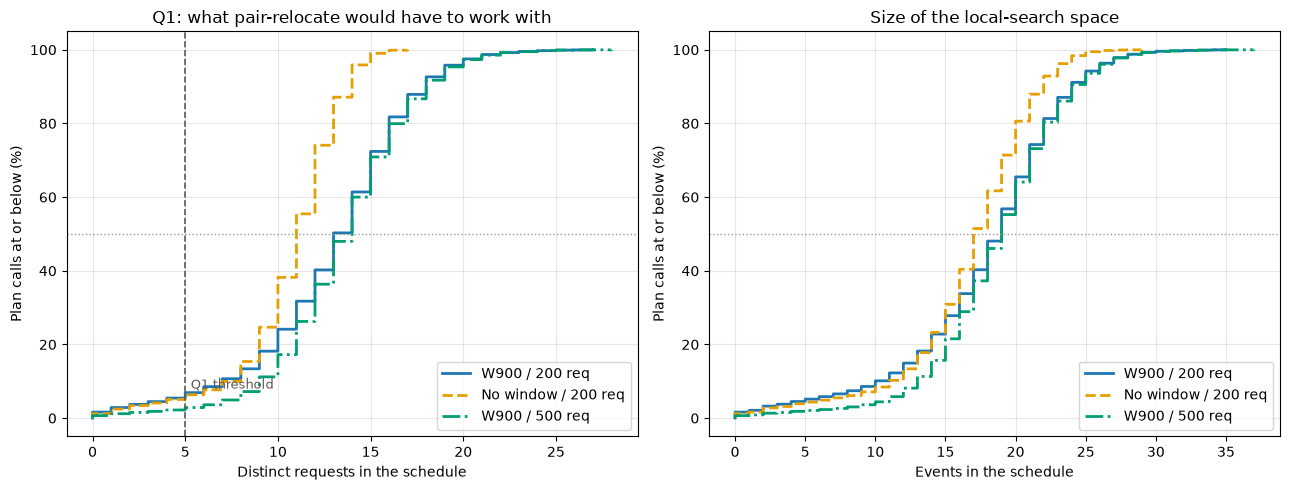

In [6]:
# Colourblind-safe triple in fixed order (checked for CVD separation, worst
# adjacent pair dE 11.4 under protanopia). Dash patterns repeat the
# distinction so the panels survive greyscale printing.
COLUMN_STYLE: dict[str, tuple[str, str]] = {
    LABEL_W900: ("#1f77b4", "-"),
    LABEL_NOWIN: ("#e69f00", "--"),
    LABEL_W900_HEAVY: ("#009e73", "-."),
}


def plot_cdf(ax: Axes, values: list[int], label: str) -> None:
    """
    Draw the empirical CDF of a count distribution as a step line.
    :param ax: Axes to draw into.
    :param values: Sampled counts, in any order.
    :param label: Column label; selects the colour and dash pattern.
    """
    if not values:
        return
    ordered = sorted(values)
    shares = [100.0 * (rank + 1) / len(ordered)
              for rank in range(len(ordered))]
    colour, dashes = COLUMN_STYLE[label]
    ax.step(ordered, shares, where="post", color=colour, linestyle=dashes,
            linewidth=2, label=label)


fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))

for column in COLUMNS:
    plot_cdf(left, STATS[column].owner_counts, column)
    plot_cdf(right, STATS[column].event_counts, column)

left.set_xlabel("Distinct requests in the schedule")
left.set_title("Q1: what pair-relocate would have to work with")
right.set_xlabel("Events in the schedule")
right.set_title("Size of the local-search space")

for ax in (left, right):
    ax.set_ylabel("Plan calls at or below (%)")
    ax.axhline(50, color="0.6", linewidth=1, linestyle=":")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right")

# The Q1 threshold: a median of 5 requests is where reordering was judged
# worth building.
left.axvline(5, color="0.35", linewidth=1.2, linestyle="--")
left.annotate("Q1 threshold", xy=(5, 8), xytext=(5.3, 8),
              fontsize=9, color="0.35")

fig.tight_layout()
plt.show()

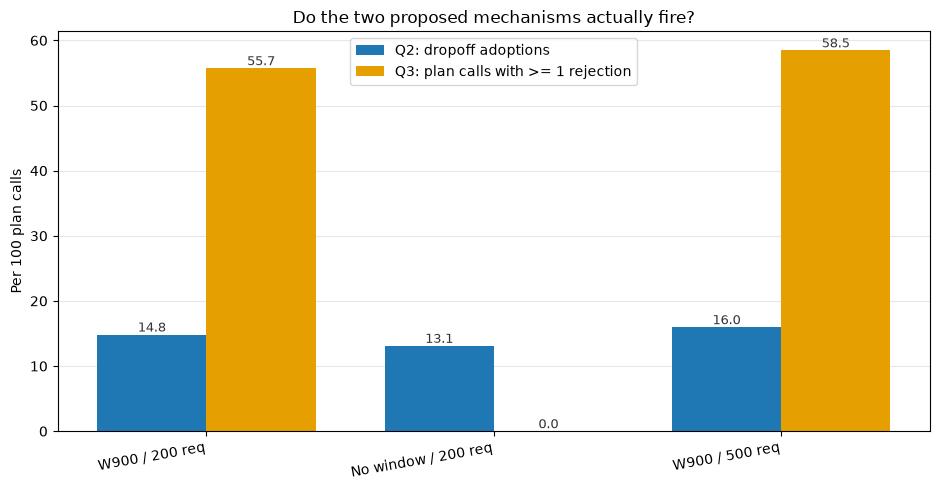

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 5))

positions = range(len(COLUMNS))
width = 0.38
adoption = [rate(STATS[c].adoptions, STATS[c].plan_calls) for c in COLUMNS]
triggers = [
    rate(STATS[c].plans_with_rejection, STATS[c].plan_calls)
    for c in COLUMNS
]
left_x = [p - width / 2 for p in positions]
right_x = [p + width / 2 for p in positions]

ax.bar(left_x, adoption, width, color="#1f77b4",
       label="Q2: dropoff adoptions")
ax.bar(right_x, triggers, width, color="#e69f00",
       label="Q3: plan calls with >= 1 rejection")

# Direct labels: the exact values are the whole point of this chart, and both
# series sit below the 3:1 contrast line against the page.
for position, value in zip(left_x + right_x, adoption + triggers):
    ax.text(position, value, f"{value:.1f}", ha="center", va="bottom",
            fontsize=9, color="0.2")

ax.set_xticks(list(positions))
ax.set_xticklabels(COLUMNS, rotation=10, ha="right")
# Adoptions can exceed one per call (several unscheduled riders can board at
# one stop), so this is a rate per 100 calls rather than a bounded share.
ax.set_ylabel("Per 100 plan calls")
ax.set_title("Do the two proposed mechanisms actually fire?")
ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()

## 6. KPI context

Not the point of this notebook, but worth having on the page: these are the
same runs the counters came from, so any suspicion that the instrumented
subclass changed behaviour can be checked against the committed baselines.
The `W900 / 200 req` column should reproduce `Window 900s` from
`window-insertion-comparison.ipynb` closely (that run used 100 trials to this
one's 20, so expect wider intervals, not different means).

In [8]:
display(Markdown("**200 requests**\n\n" + summary_200.markdown))
display(Markdown("\n**500 requests**\n\n" + summary_500.markdown))

**200 requests**

| Property | W900 / 200 req | No window / 200 req |
| --- | --- | --- |
| Fulfilled requests | 182.7 (±1.3%) | 156.9 (±1.9%) |
| Cancelled requests | 17.3 (±13.2%) | 43.0 (±6.8%) |
| Mean wait time | 504.7 s (±2.1%) | 411.6 s (±2.4%) |
| P90 wait time | 858.0 s (±0.5%) | 744.4 s (±2.2%) |
| Mean ride time | 564.5 s (±5.2%) | 366.3 s (±3.3%) |
| Fulfillment rate | 91.3 % (±1.3%) | 78.5 % (±1.9%) |
| Served fraction | 91.3 % (±1.3%) | 78.5 % (±1.9%) |
| Throughput | 0.8 req/min (±1.5%) | 0.7 req/min (±2.1%) |
| Tick snapshots | 13254.0 (±0.5%) | 12943.6 (±0.6%) |
| Fulfilled (wait samples) | 182.7 (±1.3%) | 156.9 (±1.9%) |
| Min wait time | 6.3 s (±49.6%) | 6.6 s (±66.7%) |
| Max wait time | 897.1 s (±0.1%) | 890.3 s (±0.4%) |
| Min ride time | 6.6 s (±30.1%) | 6.6 s (±19.9%) |
| Max ride time | 2995.4 s (±9.8%) | 1541.3 s (±6.7%) |


**500 requests**

| Property | W900 / 500 req |
| --- | --- |
| Fulfilled requests | 455.8 (±0.8%) |
| Cancelled requests | 44.2 (±8.5%) |
| Mean wait time | 500.5 s (±1.5%) |
| P90 wait time | 860.3 s (±0.4%) |
| Mean ride time | 571.2 s (±3.1%) |
| Fulfillment rate | 91.2 % (±0.8%) |
| Served fraction | 91.2 % (±0.8%) |
| Throughput | 0.9 req/min (±0.8%) |
| Tick snapshots | 31176.0 (±0.2%) |
| Fulfilled (wait samples) | 455.8 (±0.8%) |
| Min wait time | 1.7 s (±79.9%) |
| Max wait time | 898.4 s (±0.0%) |
| Min ride time | 4.8 s (±13.1%) |
| Max ride time | 3385.2 s (±8.1%) |

## What to look for

Answers to the four questions, and what each one implies for the next step.

**Q1 — is there a search space?** Read the bold median row, then the CDF.

- *Median >= 5 requests* → build it. Start with L1 (relocate-pair repair),
  since eject-and-reinsert composes from `Schedule.without_owner` plus the
  existing `_best_insertion` and needs almost no new machinery.
- *Median <= 2, P90 <= 3* → there is nothing to reorder at this load, and the
  honest conclusion is that reordering is not where the remaining value is.
  Check the 500-request column before dropping the direction entirely.
- *Marginal* → look at the ">= 4 requests" share. If a quarter of plan calls
  clear it, an event-triggered pass that only runs on those calls is still
  worth it; if it is a few percent, it is not.

**Q2 — adoption.** The bold adoptions row.

- *Materially above zero* → opportunistic boarding really does perturb the
  order, and the third strand of the argument for reordering stands.
- *Near zero* → retract that strand. It would mean `BusAgent._board` rarely
  catches anyone the policy rejected, which would itself be worth knowing —
  it bears on how much the soft-skip model actually costs.

**Q3 — the trigger.** The bold rejection-trigger row.

- *Comfortably above zero at W900* → event-triggered L1 is viable, and is the
  cheapest way to buy reordering.
- *Near zero* → the trigger never fires; fall back to round-robin selection,
  which costs a fixed amount per call whether or not there is anything to fix.

Also compare the two rejection rows against each other. A large gap between
"rejected attempts" and "plan calls with >= 1 rejection" confirms that most
rejections are re-attempts of the same handful of unreachable requests, which
would mean the insertion loop is spending real time on requests it has already
refused several times over — a separate and possibly easier optimisation than
reordering.

**Q4 — load.** Compare the two W900 columns.

- *Headroom appears only at 500 requests* → reordering is a scaling feature,
  not a general one. Worth building, but it should be evaluated at high load
  and the campus-scale results should not be expected to move.
- *Both columns look the same* → schedule length is bounded by something other
  than demand (most likely the service window itself, which caps how far ahead
  the policy will commit), and more load will not create headroom.

**Also worth reading off:** the plan-call counts and the cost-check timings
together give the current per-plan cost. That is the budget any reorder step
has to fit inside, and the number to quote when the question becomes whether
this can run in real time under CARLA.

### A caveat on reproducibility

Re-running in a fresh kernel can shift numbers slightly: Python randomizes
string hashing per process, and several policies break ties with `min()` over a
`set[str]`. `WindowInsertionPolicy` appeared immune in the last sweep, but the
counters here are finer-grained than anything measured before, so set
`PYTHONHASHSEED=0` before launching Jupyter if these numbers are going to be
quoted anywhere.

### If the answer is "build it"

The proposed ladder, cheapest first:

- **L1 — relocate-pair repair.** Eject one request, reinsert at its best
  feasible slot pair, keep only if the total cost strictly improves. Composes
  from methods that already exist.
- **L2 — ruin and recreate.** Eject a related subset, reinsert in a fresh
  (regret-ordered) sequence. Escapes the local optima L1 cannot.
- **L3 — total reorder every epoch.** Cheapest to write, most expensive to run,
  and it discards the stability the persistent schedule was introduced to
  provide — a probe of whether persistence was worth anything, not an
  incremental improvement.

Whichever is built, it should be a constructor flag on `WindowInsertionPolicy`
rather than a new class, so the L0 control stays one column in the same
`summarize_comparison` call. And a reorder must be rejected outright unless
every ejected request is successfully reinserted: the window guarantee is the
policy's selling point and is worth more than a marginal cost improvement.